# Praktik  RET503 (YOLO) — Notebook Siti


In [1]:
!nvidia-smi | head -15

Fri Oct 16 13:27:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q -U ultralytics opencv-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 10.7 MB/s eta 0:00:00


In [3]:
from google.colab import files
import zipfile, glob, os, shutil
up = files.upload()
zipfile.ZipFile(list(up)[0]).extractall('/content/praktik_src')
src = os.path.dirname(glob.glob('/content/praktik_src/**/06_latih_bandingkan.py', recursive=True)[0])
os.makedirs('/content/kerja', exist_ok=True)
for f in glob.glob(src + '/*.py'):
    shutil.copy(f, '/content/kerja/')
os.chdir('/content/kerja')
print(sorted(os.listdir('.')))

Saving YOLO.zip to YOLO.zip
['00_ambil_subset_coco.py', '01_cek_anotasi.py', '02_yolo_ke_coco.py', '03_coco_ke_yolo.py', '05_split_dataset_yolo.py', '06_latih_bandingkan.py']


In [4]:
NIM   = "4222401071"
NAMA  = "Siti Robbiah Al-Hidayah"
KELAS = "person cup tv"
JUMLAH = 300

In [5]:
!python 00_ambil_subset_coco.py --kelas {KELAS} --jumlah {JUMLAH}

Kelas dipilih: ['person', 'cup', 'tv'] | jumlah gambar: 300
(Ubah dengan: python 00_ambil_subset_coco.py --kelas <nama1> <nama2> --jumlah <n>)

Mengunduh http://images.cocodataset.org/zips/val2017.zip ... (bisa beberapa menit)
Mengekstrak val2017.zip ...
Mengunduh http://images.cocodataset.org/annotations/annotations_trainval2017.zip ... (bisa beberapa menit)
Mengekstrak annotations_trainval2017.zip ...
Kelas baru      : 0 = person, 1 = cup, 2 = tv
Gambar berobjek : 300
Gambar latar    : 30
Jumlah kotak    : person 1065, cup 119, tv 33
Siap di dataset_yolo/ -> lanjutkan dengan: python 01_cek_anotasi.py dataset_yolo


Gambar          : 330
Tanpa file label: 0
Label kosong    : 30 (gambar latar tanpa objek)
Jumlah kotak per kelas:
  person    : 1065
  cup       : 119
  tv        : 33

89 masalah ditemukan:
  [!] 000000028993.txt baris 3: kotak sangat kecil (8x22 px)
  [!] 000000028993.txt baris 5: kotak sangat kecil (7x25 px)
  [!] 000000028993.txt baris 9: kotak sangat kecil (7x24 px)
  [!] 000000033221.txt baris 7: kotak sangat kecil (6x19 px)
  [!] 000000033854.txt baris 7: kotak sangat kecil (4x12 px)
  [!] 000000033854.txt baris 9: kotak sangat kecil (5x11 px)
  [!] 000000033854.txt baris 11: kotak sangat kecil (6x11 px)
  [!] 000000033854.txt baris 13: kotak sangat kecil (7x10 px)
  [!] 000000047801.txt baris 4: kotak sangat kecil (5x20 px)
  [!] 000000047801.txt baris 5: kotak sangat kecil (6x12 px)
  [!] 000000055167.txt baris 1: kotak sangat kecil (6x18 px)
  [!] 000000055167.txt baris 3: kotak sangat kecil (7x12 px)
  [!] 000000055167.txt baris 4: kotak sangat kecil (4x21 px)
  [!] 00000005

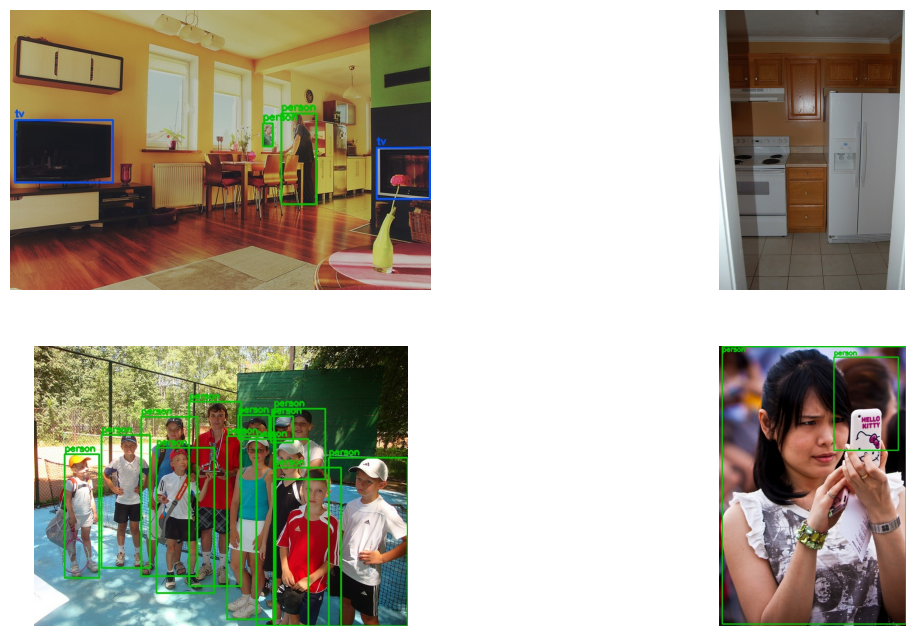

In [6]:
!python 01_cek_anotasi.py dataset_yolo
import glob, matplotlib.pyplot as plt, matplotlib.image as mpimg
fs = sorted(glob.glob('dataset_yolo/cek_visual/*.jpg'))[:4]
plt.figure(figsize=(14, 8))
for i, f in enumerate(fs):
    plt.subplot(2, 2, i + 1); plt.imshow(mpimg.imread(f)); plt.axis('off')
plt.show()

In [7]:
!python 02_yolo_ke_coco.py dataset_yolo dataset_yolo/annotations_coco.json
!python 03_coco_ke_yolo.py dataset_yolo/annotations_coco.json hasil_balik

330 gambar, 1217 kotak, 3 kategori -> dataset_yolo/annotations_coco.json
330 file label dibuat di hasil_balik/labels


In [8]:
!python 05_split_dataset_yolo.py dataset_yolo dataset_v1

train: 230 gambar
val  : 66 gambar
test : 34 gambar

data.yaml dibuat di dataset_v1/data.yaml


In [9]:
!python 06_latih_bandingkan.py --nim {NIM} --nama "{NAMA}" --epochs 2 --device 0

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

=== E1_pretrained: yolo26n.pt | pretrained=True | pengaturan dasar ===
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=Tr

In [10]:
!python 06_latih_bandingkan.py --nim {NIM} --nama "{NAMA}" --device 0


=== E1_pretrained: yolo26n.pt | pretrained=True | pengaturan dasar ===
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na

  PRAKTIK TERPADU MINGGU 4-7 - RET503
  NIM / Nama    : 4222401071 / Siti Robbiah Al-Hidayah
  Waktu         : 16-10-2026 13:38:23
  Komputer/user : 0267395836e1 / root
  Dataset       : dataset_v1  (sidik jari label: B12C14E55348)
  Pengaturan    : model yolo26n, epochs 30, imgsz 416, batch 16
  Eksperimen     Perubahan        mAP50  mAP50-95      P      R     ms   menit
  E1_pretrained  -                0.532     0.391  0.869  0.462    6.9     2.0
  E2_scratch     -                0.014     0.003  0.714  0.027    4.0     1.9
  E3_tuning      imgsz=640        0.795     0.525  0.762  0.706    8.0     2.5
  Model terpilih (mAP50-95 val tertinggi): E3_tuning
  Hasil di data TEST (sekali saja)       : mAP50 0.808 | mAP50-95 0.578



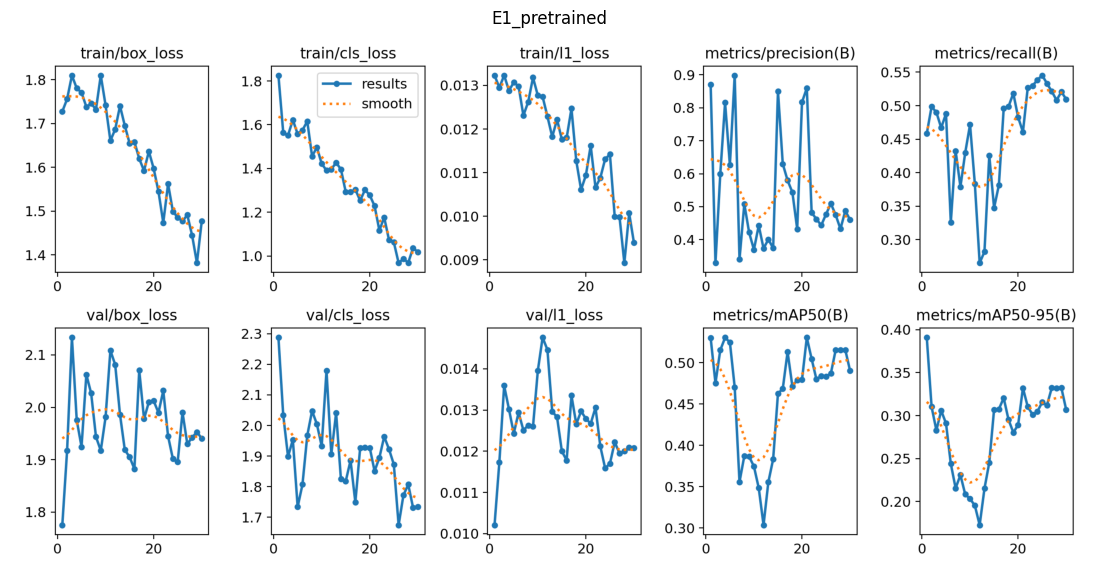

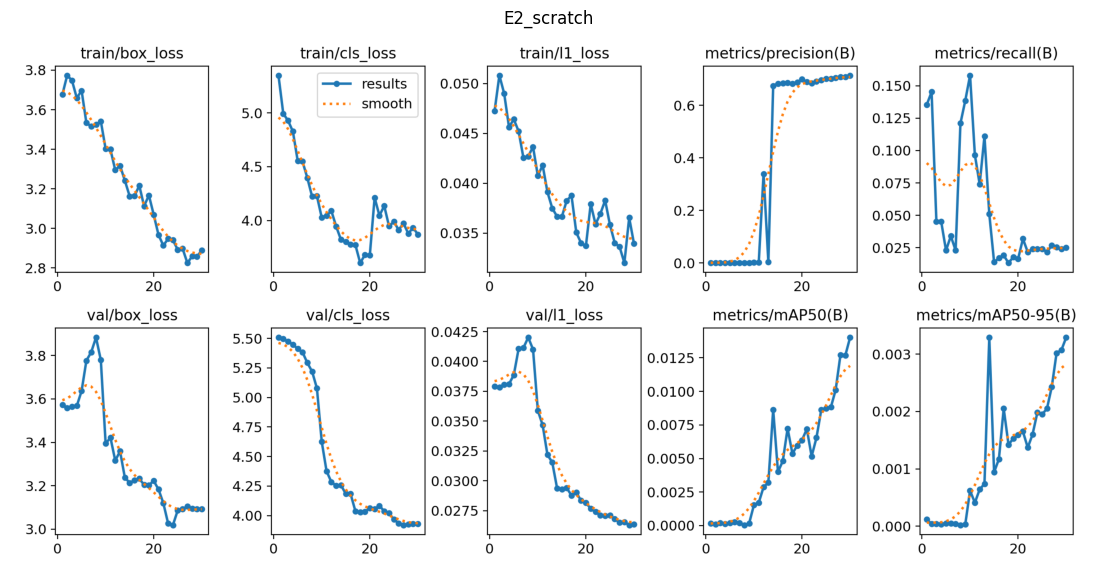

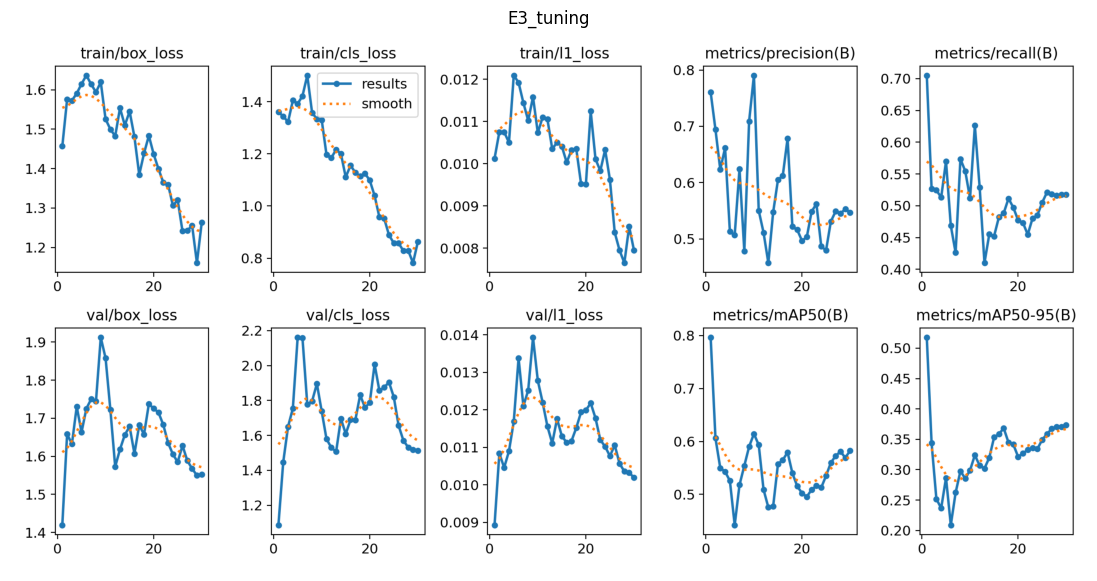

In [11]:
print(open(f'hasil_praktik_{NIM}.txt').read())
import matplotlib.pyplot as plt, matplotlib.image as mpimg
for n in ['E1_pretrained', 'E2_scratch', 'E3_tuning']:
    plt.figure(figsize=(14, 7)); plt.imshow(mpimg.imread(f'hasil_praktik/{n}/results.png')); plt.axis('off'); plt.title(n); plt.show()

In [12]:
import shutil, os
out = f'kumpulan_{NIM}'
shutil.rmtree(out, ignore_errors=True); os.makedirs(out)
shutil.copy(f'hasil_praktik_{NIM}.txt', out); shutil.copy(f'hasil_praktik_{NIM}.csv', out)
for n in ['E1_pretrained', 'E2_scratch', 'E3_tuning']:
    d = f'hasil_praktik/{n}'
    for f in ['results.png', 'results.csv', 'confusion_matrix.png', 'args.yaml']:
        if os.path.exists(f'{d}/{f}'):
            shutil.copy(f'{d}/{f}', f'{out}/{n}_{f}')
    shutil.copy(f'{d}/weights/best.pt', f'{out}/{n}_best.pt') if n != 'E2_scratch' else None
shutil.make_archive('dataset_v1', 'zip', 'dataset_v1')
shutil.move('dataset_v1.zip', out)
shutil.make_archive(out, 'zip', out)
from google.colab import files
files.download(out + '.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>